### Read data

In [6]:
import pandas as pd

df = pd.read_csv("https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv")
df.head()

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,Europe,Gasoline,Front-wheel drive,4,2180,6,243.0,3870,NaN,31.9
1,2008,Europe,Diesel,Front-wheel drive,4,2390,6,272.0,4210,NaN,31.3
2,1996,Asia,Gasoline,Front-wheel drive,5,2320,6,267.0,4240,17.3,27.5
3,1989,Europe,Gasoline,Front-wheel drive,4,2130,6,258.0,4490,18.7,28.5
4,1994,USA,Diesel,Front-wheel drive,3,2580,7,304.0,4510,17.5,31.0


### Preparing the dataset

In [7]:
df.isna().sum()

model_year               0
origin                   0
fuel_type                0
drivetrain               0
num_doors                0
engine_displacement      0
num_cylinders            0
horsepower             877
vehicle_weight           0
acceleration           264
fuel_efficiency_mpg      0
dtype: int64

In [8]:
df['horsepower'] = df['horsepower'].fillna(value=0.0)
df['acceleration'] = df['acceleration'].fillna(value=0.0)
df.isna().sum()

model_year             0
origin                 0
fuel_type              0
drivetrain             0
num_doors              0
engine_displacement    0
num_cylinders          0
horsepower             0
vehicle_weight         0
acceleration           0
fuel_efficiency_mpg    0
dtype: int64

In [9]:
from sklearn.model_selection import train_test_split

df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

print(f"train data shape: {df_train.shape}")
print(f"val data shape: {df_val.shape}")
print(f"test data shape: {df_test.shape}")

train data shape: (6000, 11)
val data shape: (2000, 11)
test data shape: (2000, 11)


In [10]:
from sklearn.feature_extraction import DictVectorizer

data_dict = df_train.to_dict(orient='records')
vectorizer = DictVectorizer(sparse=False)
enc_train_data = vectorizer.fit_transform(data_dict)
enc_train_df = pd.DataFrame(enc_train_data, columns=vectorizer.get_feature_names_out())
enc_train_df.head()

,acceleration,drivetrain=All-wheel drive,drivetrain=Front-wheel drive,drivetrain=Rear-wheel drive,engine_displacement,fuel_efficiency_mpg,fuel_type=Diesel,fuel_type=Gasoline,fuel_type=Hybrid,horsepower,model_year,num_cylinders,num_doors,origin=Asia,origin=Europe,origin=USA,vehicle_weight
0,19.0,0.0,1.0,0.0,2370.0,30.8,0.0,1.0,0.0,284.0,2011.0,6.0,4.0,0.0,0.0,1.0,4280.0
1,18.8,1.0,0.0,0.0,2460.0,29.7,1.0,0.0,0.0,288.0,2012.0,6.0,3.0,0.0,0.0,1.0,4580.0
2,20.6,1.0,0.0,0.0,2070.0,27.6,0.0,1.0,0.0,230.0,1985.0,6.0,3.0,0.0,1.0,0.0,4150.0
3,0.0,0.0,1.0,0.0,2050.0,33.7,1.0,0.0,0.0,249.0,2005.0,5.0,5.0,0.0,1.0,0.0,4120.0
4,17.9,0.0,1.0,0.0,2160.0,29.3,0.0,1.0,0.0,241.0,2004.0,6.0,2.0,1.0,0.0,0.0,4020.0


In [11]:
enc_val_data = vectorizer.transform(df_val.to_dict(orient='records'))
enc_val_df = pd.DataFrame(enc_val_data, columns=vectorizer.get_feature_names_out())
enc_val_df.head()

,acceleration,drivetrain=All-wheel drive,drivetrain=Front-wheel drive,drivetrain=Rear-wheel drive,engine_displacement,fuel_efficiency_mpg,fuel_type=Diesel,fuel_type=Gasoline,fuel_type=Hybrid,horsepower,model_year,num_cylinders,num_doors,origin=Asia,origin=Europe,origin=USA,vehicle_weight
0,18.2,0.0,1.0,0.0,2290.0,28.8,0.0,1.0,0.0,263.0,1992.0,7.0,2.0,0.0,0.0,1.0,4440.0
1,20.2,0.0,1.0,0.0,2410.0,29.6,0.0,1.0,0.0,267.0,1996.0,6.0,4.0,0.0,1.0,0.0,4380.0
2,18.6,1.0,0.0,0.0,1820.0,31.1,0.0,1.0,0.0,215.0,1994.0,6.0,3.0,0.0,1.0,0.0,3920.0
3,20.1,0.0,1.0,0.0,2370.0,28.0,0.0,1.0,0.0,249.0,1976.0,7.0,4.0,0.0,1.0,0.0,4430.0
4,18.1,1.0,0.0,0.0,2430.0,28.6,0.0,1.0,0.0,0.0,2013.0,6.0,2.0,0.0,0.0,1.0,4440.0


In [12]:
enc_test_data = vectorizer.transform(df_test.to_dict(orient='records'))
enc_test_df = pd.DataFrame(enc_test_data, columns=vectorizer.get_feature_names_out())
enc_test_df.head()

,acceleration,drivetrain=All-wheel drive,drivetrain=Front-wheel drive,drivetrain=Rear-wheel drive,engine_displacement,fuel_efficiency_mpg,fuel_type=Diesel,fuel_type=Gasoline,fuel_type=Hybrid,horsepower,model_year,num_cylinders,num_doors,origin=Asia,origin=Europe,origin=USA,vehicle_weight
0,18.5,1.0,0.0,0.0,2230.0,30.2,0.0,1.0,0.0,247.0,1978.0,6.0,3.0,1.0,0.0,0.0,4020.0
1,18.9,0.0,1.0,0.0,2120.0,31.4,0.0,0.0,1.0,235.0,1986.0,6.0,4.0,0.0,1.0,0.0,4100.0
2,19.8,0.0,0.0,1.0,2130.0,28.6,1.0,0.0,0.0,244.0,1996.0,6.0,4.0,0.0,0.0,1.0,4410.0
3,19.0,0.0,1.0,0.0,1900.0,32.6,0.0,1.0,0.0,209.0,1997.0,5.0,2.0,0.0,1.0,0.0,3590.0
4,18.5,0.0,0.0,1.0,2210.0,33.5,0.0,1.0,0.0,229.0,1992.0,6.0,4.0,0.0,1.0,0.0,4270.0


### Question 1

[Text(0.5, 0.75, 'model_year <= 1997.5\nsquared_error = 8.589\nsamples = 6000\nvalue = 30.012'),
 Text(0.25, 0.25, 'squared_error = 6.937\nsamples = 2716\nvalue = 28.614'),
 Text(0.375, 0.5, 'True  '),
 Text(0.75, 0.25, 'squared_error = 7.002\nsamples = 3284\nvalue = 31.168'),
 Text(0.625, 0.5, '  False')]

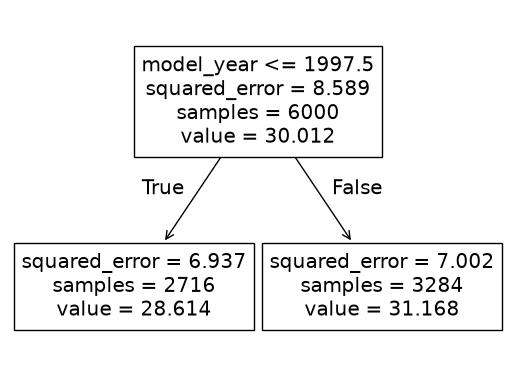

In [19]:
from sklearn.tree import DecisionTreeRegressor, plot_tree

train_data = enc_train_df.copy()
y_train = train_data.pop('fuel_efficiency_mpg')
X_train = train_data

model = DecisionTreeRegressor(max_depth=1)
model.fit(X_train, y_train)
plot_tree(model, feature_names=X_train.columns)

### Question 2

In [20]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import root_mean_squared_error

val_data = enc_val_df.copy()
y_val = val_data.pop('fuel_efficiency_mpg')
X_val = val_data

model = RandomForestRegressor(n_estimators=10, random_state=1, n_jobs=-1)

model.fit(X_train, y_train)
y_pred = model.predict(X_val)
rmse = root_mean_squared_error(y_val, y_pred)
print(f"RMSE: {rmse}")

RMSE: 1.8336350509302553


### Question 3

In [29]:
estimators = [10, 50, 100, 150]

results = {}

for estimator in estimators:
  model = RandomForestRegressor(n_estimators=estimator, random_state=1, n_jobs=-1)
  model.fit(X_train, y_train)
  y_pred = model.predict(X_val)
  results[estimator] = root_mean_squared_error(y_val, y_pred)

results = sorted(results.items(), key=lambda item:item[1], reverse=False)
print(results)

[(100, 1.7675167068517343), (150, 1.7675268275820377), (50, 1.7696263933384355), (10, 1.8336350509302553)]


### Question 4

In [30]:
depths = [10, 15, 20, 25]
results = {}

for depth in depths:
  estimators = [10, 50, 100, 150]
  rmse_scores = []
  for estimator in estimators:
    model = RandomForestRegressor(n_estimators=estimator, random_state=1, max_depth=depth, n_jobs=-1)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_val)
    rmse_scores.append(root_mean_squared_error(y_val, y_pred))
  results[depth] = sum(rmse_scores) / len(rmse_scores)

results = sorted(results.items(), key=lambda item:item[1], reverse=False)
print(results)

[(10, 1.7568661294868555), (20, 1.78267768236131), (15, 1.78478180194174), (25, 1.787372763495381)]


### Question 5

In [34]:
model = RandomForestRegressor(n_estimators=10, max_depth=20, random_state=1, n_jobs=-1)

model.fit(X_train, y_train)
importances = dict(zip(X_train.columns, model.feature_importances_))
importances = sorted(importances.items(), key=lambda item:item[1], reverse=True)
print(importances)

[('model_year', np.float64(0.2958215896737655)), ('vehicle_weight', np.float64(0.2036487269215361)), ('fuel_type=Gasoline', np.float64(0.16071285747241087)), ('horsepower', np.float64(0.07825356904805965)), ('engine_displacement', np.float64(0.0610078885955866)), ('acceleration', np.float64(0.055466223754224504)), ('origin=USA', np.float64(0.04223246926448611)), ('fuel_type=Diesel', np.float64(0.021127583198586843)), ('drivetrain=Front-wheel drive', np.float64(0.0200048032335583)), ('num_doors', np.float64(0.019723750114378893)), ('fuel_type=Hybrid', np.float64(0.011685408465443874)), ('drivetrain=All-wheel drive', np.float64(0.007872747899466636)), ('num_cylinders', np.float64(0.006938921275657379)), ('origin=Asia', np.float64(0.006478617291960995)), ('drivetrain=Rear-wheel drive', np.float64(0.005636066805696865)), ('origin=Europe', np.float64(0.0033887769851809724))]


### Question 6

In [35]:
!pip install xgboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 131.7/131.7 MB 32.3 MB/s  0:00:04m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 351.5/351.5 MB 23.5 MB/s  0:00:11m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [xgboost]m1/2 [xgboost]


In [41]:
import xgboost as xgb

dtrain = xgb.DMatrix(X_train, label=y_train)
dval = xgb.DMatrix(X_val, label=y_val)

param = {'max_depth':6, 'eta':0.3, 'min_child_weight':1, 'objective':'reg:squarederror', 'nthread':8, 'seed':1, 'verbosity':1}
model1 = xgb.train(params=param, dtrain=dtrain, num_boost_round=100)
pred1 = model1.predict(dval)

rmse1 = root_mean_squared_error(y_val, pred1)
print(f"for eta=0.3 rmse={rmse1}")

param['eta'] = 0.1
model2 = xgb.train(params=param, dtrain=dtrain, num_boost_round=100)
pred2 = model2.predict(dval)

rmse2 = root_mean_squared_error(y_val, pred2)
print(f"for eta=0.1 rmse={rmse2}")

for eta=0.3 rmse=1.8264579799904583
for eta=0.1 rmse=1.724810059827976
